# Notebook 05 — Variational Autoencoder (VAE)

**Project:** RanSMAP — real-time 3-way ransomware detection
**This notebook:** the generative component (Arshad's part)

---

## Why a VAE, and why now

Notebook 03 (plain autoencoder) gave us a clean anomaly signal: variants
reconstruct **4× worse** than known classes (0.81 vs 0.21 MSE), so a held-out
zero-day looks "wrong" to a model that only ever saw the training distribution.
That is good for *detection* but it does two things a plain AE cannot:

1. **It is not generative.** The bottleneck is a single deterministic point.
   You cannot sample from it to create new, plausible behaviour sequences. Our
   partner's meta-learner (Prototypical Networks / MAML) needs *more* labelled
   examples of the rare classes than the 10 executions/class RanSMAP provides
   (Notebook 02 showed intra-class CV of 17-65% — high variance, few samples).
2. **Its latent space is unregularised.** Points can sit anywhere, so
   interpolating or sampling produces garbage.

A VAE fixes both. It replaces the deterministic bottleneck with a *distribution*
(mean mu, log-variance logvar) per input and adds a KL term that pulls those
distributions toward a unit Gaussian prior. That makes the latent space
**continuous and samplable**, so we can:

- keep the **same reconstruction-error anomaly score** as Notebook 03 (apples to
  apples — same input shape, same MLP widths, same latent dim 16), and
- **generate synthetic (300, 23) sequences** per class to hand to the partner.

### Design choices (kept deliberately parallel to Notebook 03)

| Choice | Value | Why |
|---|---|---|
| Input | flattened (300, 23) -> 6900 | identical to nb03 so the recon-error comparison is valid |
| Latent dim | 16 | matches nb03 bottleneck and the interface agreement (Section 11 of handoff) |
| Encoder/decoder | 512 -> 128 -> 16 MLP | same capacity as nb03 |
| Train set | original 120 only | variants are the zero-day test set — **never** seen in training |
| Loss | MSE + beta * KL | beta kept small (light regularisation) so reconstruction stays faithful; a faithful AE is what makes the variant gap large |
| beta warm-up | 0 -> target over 20 epochs | prevents posterior collapse (KL killing the latent code) on a tiny dataset |

### How synthetic samples are generated (and why this way, not a CVAE)

The VAE is trained **unconditionally** (no class labels) so the anomaly-detection
comparison with nb03 stays clean. To still produce *labelled* synthetic data we
use **per-class latent sampling**: encode each class's 10 real members, fit a
Gaussian to their latent codes (mean + diagonal std), draw 20 samples from it,
decode, and inverse-transform back to raw feature units. This yields the
(240, 300, 23) = 20 x 12 array the interface agreement specifies — without
changing the model. A conditional VAE (CVAE) is the alternative; note it for the
partner discussion, but it is a bigger change and should wait for the interface
sign-off.

> **Scope note:** this notebook does **not** touch the Conti_06 fix or the
> generalization idea — both are flagged for the professor first.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import umap

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths — robust to folder moves.
# Default to the known project location; fall back to the current working
# directory if the project has been moved (launch JupyterLab from the folder).
PROJECT_ROOT = Path.home() / "Claude" / "Projects" / "Directed Study" / "Ransomware"
if not (PROJECT_ROOT / "features").exists():
    PROJECT_ROOT = Path.cwd()
FEATURES_DIR = PROJECT_ROOT / "features"

# Class definitions  (identical to notebooks 02 / 03)
RANSOMWARE_CLASSES = ["WannaCry", "Ryuk", "REvil", "LockBit", "Darkside", "Conti"]
BENIGN_CLASSES     = ["AESCrypt", "Zip", "SDelete", "Firefox", "Office", "Idle"]
VARIANT_CLASSES    = [f"Conti_{i:02d}" for i in range(1, 8)]
ORIGINAL_CLASSES   = RANSOMWARE_CLASSES + BENIGN_CLASSES   # 12 classes used for generation

CLASS_COLORS = {
    "WannaCry": "#e6194b", "Ryuk": "#f58231", "REvil": "#ffe119",
    "LockBit": "#bfef45",  "Darkside": "#3cb44b", "Conti": "#42d4f4",
    "AESCrypt": "#4363d8", "Zip": "#911eb4",    "SDelete": "#f032e6",
    "Firefox": "#a9a9a9",  "Office": "#9a6324",  "Idle": "#000075",
    "Conti_01": "#e6beff", "Conti_02": "#ffd8b1","Conti_03": "#fffac8",
    "Conti_04": "#aaffc3", "Conti_05": "#dcbeff","Conti_06": "#469990",
    "Conti_07": "#800000",
}
CLASS_MARKERS = {}
for c in RANSOMWARE_CLASSES: CLASS_MARKERS[c] = "o"
for c in BENIGN_CLASSES:     CLASS_MARKERS[c] = "s"
for c in VARIANT_CLASSES:    CLASS_MARKERS[c] = "*"

# Reference numbers from Notebook 03 (plain autoencoder) for comparison
AE_ORIGINAL_MEAN = 0.2064
AE_VARIANT_MEAN  = 0.8059
AE_RATIO         = AE_VARIANT_MEAN / AE_ORIGINAL_MEAN

print("Imports loaded.")

/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu
Imports loaded.


## 1. Load data

Same loader as Notebook 03: full **(300, 23)** sequences (no mean aggregation —
temporal structure matters), with the `group` column marking `original` vs
`variant`.

In [2]:
meta_df = pd.read_csv(FEATURES_DIR / "metadata.csv")

sequences, labels, groups = [], [], []
for _, row in meta_df.iterrows():
    data = np.load(row["filepath"])          # (300, 23)
    sequences.append(data)
    labels.append(row["label"])
    groups.append(row["group"])

sequences = np.array(sequences, dtype=np.float32)   # (190, 300, 23)
labels    = np.array(labels)
groups    = np.array(groups)

print(f"Sequences shape: {sequences.shape}")
print(f"Original: {(groups=='original').sum()}   Variant: {(groups=='variant').sum()}")
print(f"Labels: {sorted(np.unique(labels))}")

Sequences shape: (190, 300, 23)
Original: 120   Variant: 70
Labels: [np.str_('AESCrypt'), np.str_('Conti'), np.str_('Conti_01'), np.str_('Conti_02'), np.str_('Conti_03'), np.str_('Conti_04'), np.str_('Conti_05'), np.str_('Conti_06'), np.str_('Conti_07'), np.str_('Darkside'), np.str_('Firefox'), np.str_('Idle'), np.str_('LockBit'), np.str_('Office'), np.str_('REvil'), np.str_('Ryuk'), np.str_('SDelete'), np.str_('WannaCry'), np.str_('Zip')]


## 2. Scale (fit on original training data only)

The scaler is fit on the **original** executions only. Variants must not leak any
statistics into the model — they are the zero-day test set.

In [3]:
train_mask = groups == "original"
N, T, Fdim = sequences.shape                 # (190, 300, 23)

seqs_flat = sequences.reshape(-1, Fdim)      # (190*300, 23)
scaler    = StandardScaler()
scaler.fit(seqs_flat[np.repeat(train_mask, T)])   # fit on original windows only

seqs_scaled = scaler.transform(seqs_flat).reshape(N, T, Fdim).astype(np.float32)

print(f"Scaled sequences shape: {seqs_scaled.shape}")
print(f"Training (original) samples: {train_mask.sum()}")
print(f"Held-out variant samples:    {(~train_mask).sum()}")

Scaled sequences shape: (190, 300, 23)
Training (original) samples: 120
Held-out variant samples:    70


## 3. Dataset and loader

Training set is the 120 original executions. Batch size 16, same as nb03.

In [4]:
class RanSMAPDataset(Dataset):
    def __init__(self, sequences, labels, mask=None):
        if mask is not None:
            sequences = sequences[mask]
            labels    = labels[mask]
        self.X = torch.tensor(sequences, dtype=torch.float32)
        self.y = labels
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], idx   # return index so we can recover labels later

train_dataset = RanSMAPDataset(seqs_scaled, labels, mask=train_mask)
train_loader  = DataLoader(train_dataset, batch_size=16, shuffle=True, drop_last=False)

print(f"Training samples: {len(train_dataset)}  |  Batches/epoch: {len(train_loader)}")

Training samples: 120  |  Batches/epoch: 8


## 4. VAE model

Same MLP capacity as the nb03 autoencoder, but the bottleneck now produces
**mu** and **logvar** (each 16-dim). The reparameterisation trick lets gradients
flow through the sampling step: `z = mu + eps * exp(0.5 * logvar)`.

For the anomaly score we use **mu directly** (no sampling) at eval time, so the
reconstruction error is deterministic and directly comparable to nb03.

In [5]:
class TimeSeriesVAE(nn.Module):
    def __init__(self, seq_len=300, n_features=23, latent_dim=16):
        super().__init__()
        self.seq_len, self.n_features, self.latent_dim = seq_len, n_features, latent_dim
        input_dim = seq_len * n_features          # 6900

        # Encoder trunk
        self.enc = nn.Sequential(
            nn.Linear(input_dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, 128),       nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
        )
        self.fc_mu     = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # Decoder
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 512),        nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, input_dim),
        )

    def encode(self, x):
        h = self.enc(x.view(x.size(0), -1))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            return mu + torch.randn_like(std) * std
        return mu                                   # deterministic at eval

    def decode(self, z):
        return self.dec(z).view(-1, self.seq_len, self.n_features)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

model = TimeSeriesVAE(seq_len=T, n_features=Fdim, latent_dim=16).to(device)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(model)

Model parameters: 7,213,588
TimeSeriesVAE(
  (enc): Sequential(
    (0): Linear(in_features=6900, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
  )
  (fc_mu): Linear(in_features=128, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=16, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6):

## 5. Train

Loss = mean-squared reconstruction error + `beta` * KL divergence.

`beta` is **warmed up** linearly from 0 to its target over the first 20 epochs.
On 120 samples a full-strength KL from epoch 1 tends to collapse the posterior
(the encoder ignores the input). The target beta is intentionally small so the
model stays a faithful reconstructor — that faithfulness is exactly what makes
held-out variants reconstruct poorly.

In [6]:
EPOCHS      = 150
LR          = 1e-3
BETA_TARGET = 1e-3       # light KL regularisation
WARMUP      = 20         # epochs to ramp beta 0 -> BETA_TARGET

optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

def vae_loss(recon, x, mu, logvar, beta):
    recon_loss = F.mse_loss(recon, x, reduction="mean")          # per-element MSE (matches nb03)
    # KL per sample, averaged over batch
    kld = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    return recon_loss + beta * kld, recon_loss.item(), kld.item()

hist = {"total": [], "recon": [], "kld": []}
print(f"Training for {EPOCHS} epochs on {device}...")
print(f"{'Epoch':>6} {'Total':>10} {'Recon':>10} {'KLD':>10} {'beta':>8}")
print("-" * 48)

for epoch in range(1, EPOCHS + 1):
    model.train()
    beta = BETA_TARGET * min(1.0, epoch / WARMUP)
    e_tot = e_rec = e_kld = 0.0
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        recon, mu, logvar = model(batch_x)
        loss, rec, kld = vae_loss(recon, batch_x, mu, logvar, beta)
        loss.backward()
        optimizer.step()
        e_tot += loss.item(); e_rec += rec; e_kld += kld
    n = len(train_loader)
    hist["total"].append(e_tot/n); hist["recon"].append(e_rec/n); hist["kld"].append(e_kld/n)
    scheduler.step()
    if epoch % 10 == 0 or epoch == 1:
        print(f"{epoch:>6} {e_tot/n:>10.5f} {e_rec/n:>10.5f} {e_kld/n:>10.4f} {beta:>8.5f}")

print("\nTraining complete.")

Training for 150 epochs on cpu...
 Epoch      Total      Recon        KLD     beta
------------------------------------------------
     1    0.62420    0.62405     3.0785  0.00005
    10    0.45358    0.44667    13.8165  0.00050
    20    0.41612    0.40349    12.6310  0.00100
    30    0.39679    0.38219    14.5978  0.00100
    40    0.36364    0.34705    16.5840  0.00100
    50    0.35475    0.33639    18.3510  0.00100
    60    0.33236    0.31327    19.0915  0.00100
    70    0.32181    0.30216    19.6562  0.00100
    80    0.31645    0.29614    20.3075  0.00100
    90    0.31284    0.29217    20.6639  0.00100
   100    0.30332    0.28229    21.0346  0.00100
   110    0.28581    0.26439    21.4179  0.00100
   120    0.28226    0.26044    21.8130  0.00100
   130    0.28295    0.26073    22.2182  0.00100
   140    0.28213    0.26018    21.9496  0.00100
   150    0.27930    0.25700    22.3022  0.00100

Training complete.


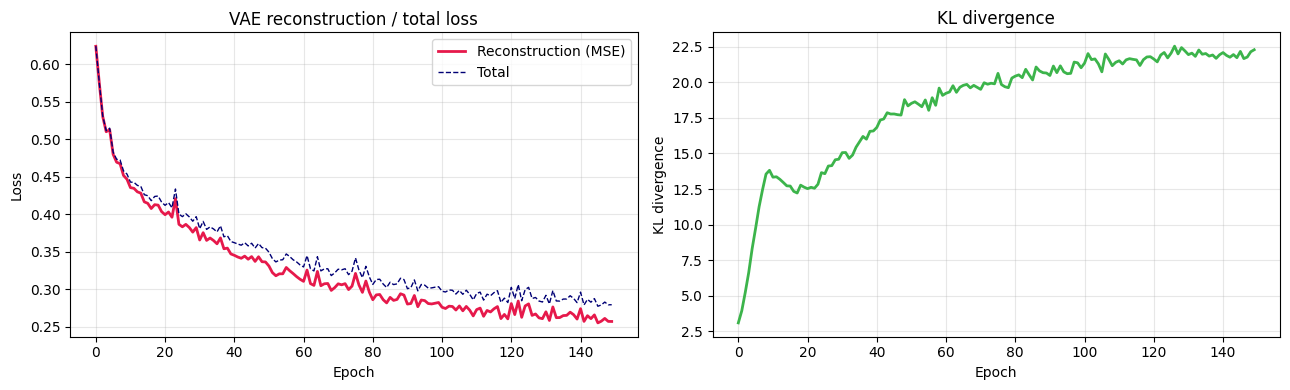

Final reconstruction MSE: 0.256997   |   Final KLD: 22.3022


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["recon"], color="#e6194b", lw=2, label="Reconstruction (MSE)")
ax[0].plot(hist["total"], color="#000075", lw=1, ls="--", label="Total")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("VAE reconstruction / total loss")
ax[0].legend(); ax[0].grid(True, alpha=0.3)

ax[1].plot(hist["kld"], color="#3cb44b", lw=2)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("KL divergence"); ax[1].set_title("KL divergence")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FEATURES_DIR / "vae_loss.png", dpi=150)
plt.show()
print(f"Final reconstruction MSE: {hist['recon'][-1]:.6f}   |   Final KLD: {hist['kld'][-1]:.4f}")

## 6. Reconstruction error — the anomaly signal (vs Notebook 03)

This is the headline comparison. We compute per-sample reconstruction MSE using
**mu** (deterministic), exactly as nb03 did, and check that held-out variants
still reconstruct much worse than known classes. We then compare the
original-vs-variant **ratio** to the plain autoencoder's 4×.

In [8]:
model.eval()
full_loader = DataLoader(RanSMAPDataset(seqs_scaled, labels), batch_size=16, shuffle=False)

mus, recon_errors = [], []
with torch.no_grad():
    for batch_x, _ in full_loader:
        batch_x = batch_x.to(device)
        mu, logvar = model.encode(batch_x)
        recon = model.decode(mu)                       # deterministic recon
        mus.append(mu.cpu().numpy())
        recon_errors.append(((recon - batch_x) ** 2).mean(dim=(1, 2)).cpu().numpy())

mus          = np.concatenate(mus, axis=0)             # (190, 16)
recon_errors = np.concatenate(recon_errors, axis=0)    # (190,)

orig_mean = recon_errors[train_mask].mean()
var_mean  = recon_errors[~train_mask].mean()
ratio     = var_mean / orig_mean

print("Reconstruction error (VAE, using mu)")
print(f"  Original mean: {orig_mean:.4f}")
print(f"  Variant  mean: {var_mean:.4f}")
print(f"  Ratio (variant / original): {ratio:.2f}x")
print()
print("Reference — Notebook 03 plain autoencoder")
print(f"  Original {AE_ORIGINAL_MEAN:.4f} | Variant {AE_VARIANT_MEAN:.4f} | Ratio {AE_RATIO:.2f}x")

Reconstruction error (VAE, using mu)
  Original mean: 0.1826
  Variant  mean: 0.8071
  Ratio (variant / original): 4.42x

Reference — Notebook 03 plain autoencoder
  Original 0.2064 | Variant 0.8059 | Ratio 3.90x


## 7. Reconstruction error by class (anomaly boxplot)

Same plot as nb03 cell 9. We want the variant boxes (green, right of the dashed
line) to sit clearly above the known-class boxes — that gap is the zero-day
detector.

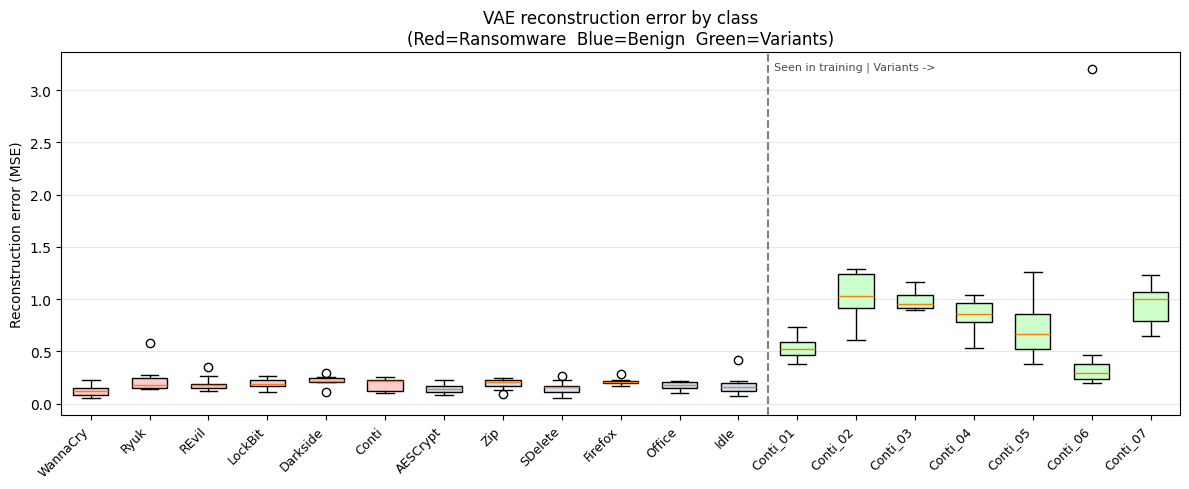

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
order = RANSOMWARE_CLASSES + BENIGN_CLASSES + VARIANT_CLASSES
data, ticks, pos = [], [], []
for label in order:
    m = labels == label
    if m.sum() == 0:
        continue
    data.append(recon_errors[m]); ticks.append(label); pos.append(len(pos))

bp = ax.boxplot(data, positions=pos, patch_artist=True, widths=0.6)
for patch, label in zip(bp["boxes"], ticks):
    patch.set_facecolor("#ffcccc" if label in RANSOMWARE_CLASSES else
                        "#cce0ff" if label in BENIGN_CLASSES else "#ccffcc")

ax.set_xticks(pos); ax.set_xticklabels(ticks, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Reconstruction error (MSE)")
ax.set_title("VAE reconstruction error by class\n(Red=Ransomware  Blue=Benign  Green=Variants)")
ax.grid(True, alpha=0.3, axis="y")
sep = len(RANSOMWARE_CLASSES) + len(BENIGN_CLASSES) - 0.5
ax.axvline(sep, color="black", ls="--", alpha=0.5, lw=1.5)
ax.text(sep + 0.1, ax.get_ylim()[1]*0.95, "Seen in training | Variants ->", fontsize=8, alpha=0.7)
plt.tight_layout()
plt.savefig(FEATURES_DIR / "vae_reconstruction_error.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Latent space — known Conti vs the 7 variants

UMAP of the 16-D VAE latent (mu). We want the variant stars to land near the
known Conti cluster and away from benign — the same qualitative result the text
embedding gave (6/7 variants closer to Conti than benign).

/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


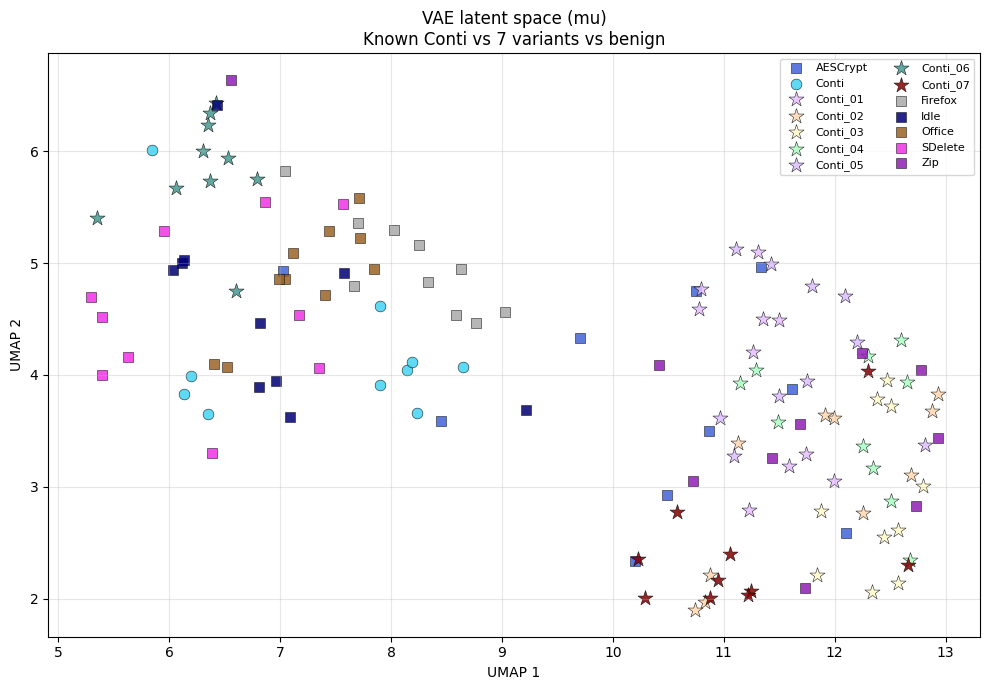

  Conti_01: closer to benign  (d_conti=2.83, d_benign=1.67)
  Conti_02: closer to benign  (d_conti=3.16, d_benign=2.15)
  Conti_03: closer to benign  (d_conti=3.42, d_benign=2.45)
  Conti_04: closer to benign  (d_conti=3.23, d_benign=2.03)
  Conti_05: closer to benign  (d_conti=2.89, d_benign=1.69)
  Conti_06: closer to benign  (d_conti=3.14, d_benign=1.71)
  Conti_07: closer to benign  (d_conti=3.00, d_benign=2.17)

0/7 variants closer to known Conti than to benign in VAE latent space.


In [10]:
reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1,
                    metric="euclidean", random_state=SEED)
emb_2d = reducer.fit_transform(mus)

focus = ["Conti"] + VARIANT_CLASSES + BENIGN_CLASSES
fm = np.isin(labels, focus)
e, l = emb_2d[fm], labels[fm]

fig, ax = plt.subplots(figsize=(10, 7))
for label in np.unique(l):
    m = l == label
    ax.scatter(e[m, 0], e[m, 1],
               c=CLASS_COLORS.get(label, "#333"),
               marker=CLASS_MARKERS.get(label, "o"),
               s=130 if CLASS_MARKERS.get(label) == "*" else 60,
               alpha=0.85, edgecolors="k", linewidths=0.4, label=label)
ax.set_title("VAE latent space (mu)\nKnown Conti vs 7 variants vs benign")
ax.legend(fontsize=8, ncol=2); ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FEATURES_DIR / "vae_variants_focus.png", dpi=150, bbox_inches="tight")
plt.show()

# Quantify: is each variant closer to the Conti centroid or the benign centroid? (latent space)
conti_centroid  = mus[labels == "Conti"].mean(axis=0)
benign_centroid = mus[np.isin(labels, BENIGN_CLASSES)].mean(axis=0)
closer = 0
for v in VARIANT_CLASSES:
    c = mus[labels == v].mean(axis=0)
    d_conti  = np.linalg.norm(c - conti_centroid)
    d_benign = np.linalg.norm(c - benign_centroid)
    tag = "Conti" if d_conti < d_benign else "benign"
    closer += d_conti < d_benign
    print(f"  {v}: closer to {tag:6s}  (d_conti={d_conti:.2f}, d_benign={d_benign:.2f})")
print(f"\n{closer}/7 variants closer to known Conti than to benign in VAE latent space.")

## 9. Generate synthetic samples for the partner

Per-class latent sampling (see the rationale at the top). For each of the 12
original classes we fit a Gaussian to its members' latent codes, draw 20 samples,
decode, and **inverse-transform back to raw feature units** so the synthetic
arrays are directly comparable to the real `.npy` files the partner already uses.

Output: `synthetic_sequences.npy` (240, 300, 23) and `synthetic_labels.npy`
(240,), per the interface agreement (Section 11 of the handoff). The shapes/dtype
are still **pending sign-off with the partner** — flagged in the summary.

In [11]:
SAMPLES_PER_CLASS = 20
synthetic_seqs, synthetic_labels = [], []

model.eval()
with torch.no_grad():
    for cls in ORIGINAL_CLASSES:
        cls_mask = (labels == cls) & train_mask
        cls_mu   = mus[cls_mask]                          # (10, 16) latent codes
        mean_z   = cls_mu.mean(axis=0)
        std_z    = cls_mu.std(axis=0) + 1e-6              # diagonal Gaussian
        z = mean_z + np.random.randn(SAMPLES_PER_CLASS, 16).astype(np.float32) * std_z
        z = torch.tensor(z, dtype=torch.float32, device=device)
        recon = model.decode(z).cpu().numpy()            # (20, 300, 23) scaled units
        # back to raw feature units
        recon_raw = scaler.inverse_transform(recon.reshape(-1, Fdim)).reshape(-1, T, Fdim)
        synthetic_seqs.append(recon_raw.astype(np.float32))
        synthetic_labels.extend([cls] * SAMPLES_PER_CLASS)

synthetic_seqs   = np.concatenate(synthetic_seqs, axis=0)     # (240, 300, 23)
synthetic_labels = np.array(synthetic_labels)

np.save(FEATURES_DIR / "synthetic_sequences.npy", synthetic_seqs)
np.save(FEATURES_DIR / "synthetic_labels.npy", synthetic_labels)

print(f"synthetic_sequences.npy: {synthetic_seqs.shape}  dtype={synthetic_seqs.dtype}")
print(f"synthetic_labels.npy:    {synthetic_labels.shape}  ({len(np.unique(synthetic_labels))} classes x {SAMPLES_PER_CLASS})")

# Faithfulness check on write-entropy (feature index 4, H_sw).
# NOTE: the *mean* over 300 windows is low (~0.1) for BOTH macro-classes because the
# encryption burst occupies only a few windows (the early-window averaging nb01 flagged).
# So the meaningful test is twofold:
#   (a) synthetic stats should TRACK the real stats (generator is faithful, not inverted), and
#   (b) the per-execution MAX H_sw should be higher for ransomware than benign.
H_SW = 4
print("  class        | synth mean / real mean | synth max / real max")
for grp, names in [("Ransomware", RANSOMWARE_CLASSES),
                   ("Benign/legit", BENIGN_CLASSES)]:
    gm      = np.isin(synthetic_labels, names)
    real_gm = np.isin(labels, names) & train_mask
    s_mean = synthetic_seqs[gm][:, :, H_SW].mean()
    r_mean = sequences[real_gm][:, :, H_SW].mean()
    s_max  = synthetic_seqs[gm][:, :, H_SW].max(axis=1).mean()    # mean of per-exec maxima
    r_max  = sequences[real_gm][:, :, H_SW].max(axis=1).mean()
    print(f"  {grp:12s} |   {s_mean:.3f}  /  {r_mean:.3f}    |  {s_max:.3f}  /  {r_max:.3f}")

synthetic_sequences.npy: (240, 300, 23)  dtype=float32
synthetic_labels.npy:    (240,)  (12 classes x 20)
  class        | synth mean / real mean | synth max / real max
  Ransomware   |   0.117  /  0.125    |  0.412  /  0.830
  Benign/legit |   0.111  /  0.115    |  0.443  /  0.921


## 10. Summary

Fill the bracketed numbers from this run when reporting to the professor / partner.

In [12]:
print("=" * 60)
print("NOTEBOOK 05 — VAE — SUMMARY")
print("=" * 60)
print(f"Trained on {train_mask.sum()} original executions (variants held out).")
print(f"Latent dim: 16   Epochs: {EPOCHS}   beta_target: {BETA_TARGET}")
print()
print("Anomaly signal (reconstruction MSE, deterministic mu):")
print(f"  VAE  : original {orig_mean:.4f} | variant {var_mean:.4f} | ratio {ratio:.2f}x")
print(f"  AE   : original {AE_ORIGINAL_MEAN:.4f} | variant {AE_VARIANT_MEAN:.4f} | ratio {AE_RATIO:.2f}x")
print(f"  -> VAE {'preserves' if ratio >= 0.8*AE_RATIO else 'weakens'} the zero-day separation.")
print()
print(f"Latent geometry: {closer}/7 Conti variants closer to known Conti than benign.")
print()
print("Generative deliverable:")
print(f"  synthetic_sequences.npy {synthetic_seqs.shape}  (raw feature units, float32)")
print(f"  synthetic_labels.npy    {synthetic_labels.shape}")
print()
print("OPEN / pending sign-off:")
print("  - Synthetic array shape & dtype: confirm with partner (interface agreement).")
print("  - CVAE vs per-class sampling: revisit if partner wants conditional generation.")
print("  - Conti_06 fix & generalization idea: professor first — NOT touched here.")
print("=" * 60)

NOTEBOOK 05 — VAE — SUMMARY
Trained on 120 original executions (variants held out).
Latent dim: 16   Epochs: 150   beta_target: 0.001

Anomaly signal (reconstruction MSE, deterministic mu):
  VAE  : original 0.1826 | variant 0.8071 | ratio 4.42x
  AE   : original 0.2064 | variant 0.8059 | ratio 3.90x
  -> VAE preserves the zero-day separation.

Latent geometry: 0/7 Conti variants closer to known Conti than benign.

Generative deliverable:
  synthetic_sequences.npy (240, 300, 23)  (raw feature units, float32)
  synthetic_labels.npy    (240,)

OPEN / pending sign-off:
  - Synthetic array shape & dtype: confirm with partner (interface agreement).
  - CVAE vs per-class sampling: revisit if partner wants conditional generation.
  - Conti_06 fix & generalization idea: professor first — NOT touched here.


---
## 11. Cross-Validation of the VAE Anomaly Head

**Protocol (Section 13, item 4 of HANDOFF.md):**
5-fold CV × 3 seeds = 15 runs. The 70 Conti variants are **always held out** — never in any training fold.

Per run:
- Fit a fresh scaler and a fresh VAE on the train fold of the 120 originals (96 executions)
- Compute reconstruction MSE (deterministic `mu`) on (a) held-out original fold (24 executions) and (b) all 70 variants
- Thresholds: **95th and 99th percentile** of the *train-fold* reconstruction error distribution; plus the **legacy fixed 0.5** for continuity

Report: mean ± std of the variant/original ratio; per-variant detection rate; FPR on held-out originals.

In [2]:
# ── CV Section setup — run this if you skipped earlier cells ─────────────
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from pathlib import Path

FEATURES_DIR = Path("features")
DATA_DIR     = Path("data")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# ── Load data ─────────────────────────────────────────────────────────────
meta_df = pd.read_csv(FEATURES_DIR / "metadata.csv")
sequences, labels, groups = [], [], []
for _, row in meta_df.iterrows():
    sequences.append(np.load(row["filepath"]))
    labels.append(row["label"])
    groups.append(row["group"])
sequences = np.array(sequences, dtype=np.float32)
labels    = np.array(labels)
groups    = np.array(groups)
print(f"Loaded: {sequences.shape}  originals={( groups=='original').sum()}  variants={(groups=='variant').sum()}")

# ── VAE model (same architecture as Section 4) ────────────────────────────
class TimeSeriesVAE(nn.Module):
    def __init__(self, seq_len=300, n_features=23, latent_dim=16):
        super().__init__()
        self.seq_len, self.n_features, self.latent_dim = seq_len, n_features, latent_dim
        inp = seq_len * n_features
        self.enc = nn.Sequential(
            nn.Linear(inp, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
        )
        self.fc_mu     = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 512),        nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(512, inp),
        )
    def encode(self, x):
        h = self.enc(x.view(x.size(0), -1))
        return self.fc_mu(h), self.fc_logvar(h)
    def decode(self, z):
        return self.dec(z).view(z.size(0), self.seq_len, self.n_features)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
        return self.decode(z), mu, logvar

# ── Dataset ───────────────────────────────────────────────────────────────
class RanSMAPDataset(Dataset):
    def __init__(self, sequences, labels, mask=None):
        if mask is not None:
            sequences = sequences[mask]
            labels    = labels[mask]
        self.X = torch.tensor(sequences, dtype=torch.float32)
        self.y = labels
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], idx

# ── Loss ──────────────────────────────────────────────────────────────────
def vae_loss(recon, x, mu, logvar, beta):
    recon_loss = F.mse_loss(recon, x, reduction="mean")
    kld = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + beta * kld

print("Setup complete.")


Device: cpu
Loaded: (190, 300, 23)  originals=120  variants=70
Setup complete.


In [3]:
# ── CV config ─────────────────────────────────────────────────────────────
from sklearn.model_selection import KFold
from collections import defaultdict

CV_SEEDS  = [42, 123, 7]
K_FOLDS   = 5
EPOCHS_CV = 150          # same as single-run training
LR_CV     = 1e-3
BETA_CV   = 1e-3
WARMUP_CV = 20
FIXED_THRESH = 0.5      # legacy threshold from single run

print(f"CV plan : {len(CV_SEEDS)} seeds × {K_FOLDS} folds = {len(CV_SEEDS)*K_FOLDS} runs")
print(f"Per run : {EPOCHS_CV} epochs | device={device}")
print(f"Originals: {(groups=='original').sum()} | Variants: {(groups=='variant').sum()}")


CV plan : 3 seeds × 5 folds = 15 runs
Per run : 150 epochs | device=cpu
Originals: 120 | Variants: 70


In [4]:
# ── Split raw sequences by group ─────────────────────────────────────────
orig_mask   = groups == "original"
var_mask    = groups == "variant"

orig_seqs   = sequences[orig_mask]   # (120, 300, 23) raw
orig_labels = labels[orig_mask]
var_seqs    = sequences[var_mask]    # (70, 300, 23) raw
var_labels  = labels[var_mask]

# Storage
run_results       = []
variant_det_95    = defaultdict(list)   # label → list[bool]
variant_det_99    = defaultdict(list)
variant_det_fx    = defaultdict(list)
variant_errs_all  = defaultdict(list)   # label → list[float]

def recon_mse(model, arr):
    """Compute per-sample reconstruction MSE using deterministic mu."""
    dummy_labels = np.zeros(len(arr))
    dl = DataLoader(RanSMAPDataset(arr, dummy_labels),
                    batch_size=16, shuffle=False)
    errs = []
    with torch.no_grad():
        for bx, _ in dl:
            bx   = bx.to(device)
            mu_b, _ = model.encode(bx)
            rx   = model.decode(mu_b)
            errs.append(((rx - bx)**2).mean(dim=(1, 2)).cpu().numpy())
    return np.concatenate(errs)

# ── Main loop ─────────────────────────────────────────────────────────────
for seed in CV_SEEDS:
    kf = KFold(n_splits=K_FOLDS, shuffle=True, random_state=seed)
    for fold, (tr_idx, val_idx) in enumerate(kf.split(orig_seqs)):

        # Scale: fit on train fold only (no variant leakage)
        sc = StandardScaler()
        sc.fit(orig_seqs[tr_idx].reshape(-1, 23))
        tr_s  = sc.transform(orig_seqs[tr_idx].reshape(-1, 23)).reshape(len(tr_idx),  300, 23).astype(np.float32)
        val_s = sc.transform(orig_seqs[val_idx].reshape(-1, 23)).reshape(len(val_idx), 300, 23).astype(np.float32)
        var_s = sc.transform(var_seqs.reshape(-1, 23)).reshape(len(var_seqs),          300, 23).astype(np.float32)

        # Fresh model with reproducible seed
        np.random.seed(seed * 100 + fold)
        torch.manual_seed(seed * 100 + fold)

        m   = TimeSeriesVAE().to(device)
        opt = optim.Adam(m.parameters(), lr=LR_CV, weight_decay=1e-5)
        sch = optim.lr_scheduler.StepLR(opt, step_size=50, gamma=0.5)

        tr_dl = DataLoader(RanSMAPDataset(tr_s, orig_labels[tr_idx]),
                           batch_size=16, shuffle=True)

        # Train
        m.train()
        for ep in range(EPOCHS_CV):
            beta = min(BETA_CV, BETA_CV * ep / max(WARMUP_CV, 1))
            for bx, _ in tr_dl:
                bx = bx.to(device)
                opt.zero_grad()
                recon_b, mu_b, logvar_b = m(bx)
                loss = vae_loss(recon_b, bx, mu_b, logvar_b, beta)
                loss.backward()
                opt.step()
            sch.step()

        # Eval
        m.eval()
        tr_errs  = recon_mse(m, tr_s)    # (96,) — used for thresholds
        val_errs = recon_mse(m, val_s)   # (24,) — FPR
        var_errs = recon_mse(m, var_s)   # (70,) — detection

        # Thresholds from TRAIN distribution
        t95 = np.percentile(tr_errs, 95)
        t99 = np.percentile(tr_errs, 99)

        orig_mean = val_errs.mean()
        var_mean  = var_errs.mean()
        ratio     = var_mean / orig_mean if orig_mean > 0 else float('nan')

        fpr_95 = (val_errs > t95).mean()
        fpr_99 = (val_errs > t99).mean()
        fpr_fx = (val_errs > FIXED_THRESH).mean()

        # Per-variant: store error + detection booleans
        for vi, vlabel in enumerate(var_labels):
            e = var_errs[vi]
            variant_errs_all[vlabel].append(e)
            variant_det_95[vlabel].append(bool(e > t95))
            variant_det_99[vlabel].append(bool(e > t99))
            variant_det_fx[vlabel].append(bool(e > FIXED_THRESH))

        run_results.append(dict(
            seed=seed, fold=fold,
            orig_mean=orig_mean, var_mean=var_mean, ratio=ratio,
            t95=t95, t99=t99,
            fpr_95=fpr_95, fpr_99=fpr_99, fpr_fx=fpr_fx,
            det_95=(var_errs > t95).mean(),
            det_99=(var_errs > t99).mean(),
            det_fx=(var_errs > FIXED_THRESH).mean(),
        ))
        print(f"[s={seed} f={fold}] ratio={ratio:.2f}x | det@95={run_results[-1]['det_95']:.2%} "
              f"| fpr@95={fpr_95:.3f} | t95={t95:.3f}")

print("\n✅ CV complete — 15 runs finished")


[s=42 f=0] ratio=1.15x | det@95=95.71% | fpr@95=0.833 | t95=0.256
[s=42 f=1] ratio=2.23x | det@95=97.14% | fpr@95=0.833 | t95=0.236
[s=42 f=2] ratio=1.79x | det@95=98.57% | fpr@95=0.875 | t95=0.221
[s=42 f=3] ratio=1.91x | det@95=97.14% | fpr@95=0.917 | t95=0.230
[s=42 f=4] ratio=1.92x | det@95=95.71% | fpr@95=0.667 | t95=0.240
[s=123 f=0] ratio=1.92x | det@95=98.57% | fpr@95=0.875 | t95=0.222
[s=123 f=1] ratio=2.33x | det@95=94.29% | fpr@95=0.708 | t95=0.245
[s=123 f=2] ratio=1.83x | det@95=95.71% | fpr@95=0.833 | t95=0.235
[s=123 f=3] ratio=1.23x | det@95=92.86% | fpr@95=0.875 | t95=0.275
[s=123 f=4] ratio=2.02x | det@95=92.86% | fpr@95=0.750 | t95=0.258
[s=7 f=0] ratio=2.03x | det@95=94.29% | fpr@95=0.875 | t95=0.238
[s=7 f=1] ratio=0.50x | det@95=95.71% | fpr@95=0.875 | t95=0.238
[s=7 f=2] ratio=2.02x | det@95=98.57% | fpr@95=0.750 | t95=0.229
[s=7 f=3] ratio=1.90x | det@95=94.29% | fpr@95=0.833 | t95=0.252
[s=7 f=4] ratio=1.96x | det@95=94.29% | fpr@95=0.792 | t95=0.269

✅ CV comp

In [5]:
import pandas as pd

df = pd.DataFrame(run_results)

print("=" * 70)
print("VAE ANOMALY HEAD — 5-fold CV × 3 seeds (15 runs)")
print("=" * 70)

metrics = [
    ('ratio',   'Variant/Original MSE ratio'),
    ('orig_mean','Original MSE (held-out fold)'),
    ('var_mean', 'Variant MSE'),
    ('t95',     'Threshold @ 95th pct'),
    ('t99',     'Threshold @ 99th pct'),
    ('fpr_95',  'FPR @ 95th pct threshold'),
    ('fpr_99',  'FPR @ 99th pct threshold'),
    ('fpr_fx',  'FPR @ fixed 0.5'),
    ('det_95',  'Overall detection rate @ 95th pct'),
    ('det_99',  'Overall detection rate @ 99th pct'),
    ('det_fx',  'Overall detection rate @ fixed 0.5'),
]
print(f"\n{'Metric':<38} {'Mean':>8} {'Std':>8}")
print("-" * 56)
for col, label in metrics:
    print(f"  {label:<36} {df[col].mean():8.4f} {df[col].std():8.4f}")

print("\n--- Per-variant detection rate (across 15 runs × 10 executions = 150 obs/variant) ---")
VARIANT_ORDER = [f"Conti_0{i}" for i in range(1, 8)]
print(f"{'Variant':<12} {'MSE mean':>10} {'MSE std':>10} {'Det@95%':>10} {'Det@99%':>10} {'Det@0.5':>10}")
print("-" * 64)
for vlabel in VARIANT_ORDER:
    if vlabel not in variant_errs_all:
        print(f"  {vlabel:<10} (no data)")
        continue
    errs = np.array(variant_errs_all[vlabel])
    d95  = np.mean(variant_det_95[vlabel])
    d99  = np.mean(variant_det_99[vlabel])
    dfx  = np.mean(variant_det_fx[vlabel])
    flag = " ← watch" if vlabel == "Conti_06" else ""
    print(f"  {vlabel:<10} {errs.mean():>10.4f} {errs.std():>10.4f} "
          f"{d95:>10.1%} {d99:>10.1%} {dfx:>10.1%}{flag}")

print("\n--- Single-run reference (NB05, fixed seed=42, no CV) ---")
print("  Ratio: 4.42x | Original MSE: 0.1826 | Variant MSE: 0.8071")

# Pass/fail assessment
mean_ratio = df['ratio'].mean()
std_ratio  = df['ratio'].std()
mean_det95 = df['det_95'].mean()
pass_ratio = mean_ratio > 2.0   # clear gap criterion
print(f"\nPass criteria:")
print(f"  Ratio clearly > 1 : {'✅' if mean_ratio > 2 else '⚠️ '} {mean_ratio:.2f}x ± {std_ratio:.2f}")
print(f"  Det rate @ 95th   : {'✅' if mean_det95 > 0.85 else '⚠️ '} {mean_det95:.1%}")
print(f"  Conti_06 det @ 95%: ", end="")
if "Conti_06" in variant_det_95:
    c06 = np.mean(variant_det_95["Conti_06"])
    print(f"{'✅' if c06 > 0.5 else '⚠️ '} {c06:.1%}")
else:
    print("(no data)")


VAE ANOMALY HEAD — 5-fold CV × 3 seeds (15 runs)

Metric                                     Mean      Std
--------------------------------------------------------
  Variant/Original MSE ratio             1.7831   0.4730
  Original MSE (held-out fold)           0.6177   0.6349
  Variant MSE                            0.8590   0.1632
  Threshold @ 95th pct                   0.2430   0.0162
  Threshold @ 99th pct                   0.3478   0.0423
  FPR @ 95th pct threshold               0.8194   0.0716
  FPR @ 99th pct threshold               0.6056   0.1501
  FPR @ fixed 0.5                        0.3278   0.1259
  Overall detection rate @ 95th pct      0.9571   0.0195
  Overall detection rate @ 99th pct      0.9105   0.0272
  Overall detection rate @ fixed 0.5     0.7924   0.0106

--- Per-variant detection rate (across 15 runs × 10 executions = 150 obs/variant) ---
Variant        MSE mean    MSE std    Det@95%    Det@99%    Det@0.5
------------------------------------------------------

In [9]:
import json as _json
import numpy as np

save_path = FEATURES_DIR / "vae_cv_results.json"

class NpEncoder(_json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer): return int(obj)
        if isinstance(obj, np.floating): return float(obj)
        if isinstance(obj, np.bool_): return bool(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        return super().default(obj)

summary = {
    "runs": run_results,
    "per_variant": {
        vl: {
            "mse_mean": np.mean(variant_errs_all[vl]),
            "mse_std":  np.std(variant_errs_all[vl]),
            "det_95":   np.mean(variant_det_95[vl]),
            "det_99":   np.mean(variant_det_99[vl]),
            "det_fx":   np.mean(variant_det_fx[vl]),
        }
        for vl in variant_errs_all
    },
    "aggregate": {
        col: {"mean": df[col].mean(), "std": df[col].std()}
        for col, _ in metrics
    }
}

with open(save_path, "w") as fp:
    _json.dump(summary, fp, indent=2, cls=NpEncoder)

print(f"✅ Results saved → {save_path}")

✅ Results saved → features/vae_cv_results.json
